**Navigation** : [Version Python](SL-12b-SpectralLogicSynthesis.ipynb) | [SL-12](SL-12-DifferentiableLogicGateNetworks.ipynb) | [Index](README.md) | [SL-13](SL-13-Discover-TPR.ipynb)

# SL-12b — Synthèse logique spectrale en C#

**Objectifs** : calculer et reconstruire un spectre de Walsh, distinguer coefficients exacts et poids ternaires, mesurer Sinkhorn puis comparer recherches discrètes. **Prérequis** : fonctions booléennes, algèbre linéaire, Monte-Carlo. **Durée** : 75 minutes.

Le [carnet Python](SL-12b-SpectralLogicSynthesis.ipynb) est la source pédagogique de ce port et présente son contexte historique. Les expériences ci-dessous étudient les mécanismes sur des instances finies ; elles ne reproduisent pas l'artefact externe et ne prétendent pas en vérifier les résultats.

In [1]:
#r "nuget: MathNet.Numerics, 5.0.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Diagnostics;
using System.Numerics;
using System.Globalization;
using System.Text;
using MathNet.Numerics.LinearAlgebra;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.CurrentCulture=CultureInfo.InvariantCulture;
Console.WriteLine($".NET {Environment.Version} ; MathNet.Numerics {typeof(Matrix<double>).Assembly.GetName().Version}");

Installed Packages MathNet.Numerics, 5.0.0

.NET 10.0.14 ; MathNet.Numerics 5.0.0.0


## 0. Convention booléenne
Un bit b devient le signe 2b−1 : vrai = +1 et faux = −1. La ligne i énumère les bits de i ; le caractère χ_S est le produit des signes de S. Au seuil, sign(0)=+1. Les quatre portes sont vérifiées exhaustivement sur deux bits.

In [2]:
int Signe(double z)=>z>=0?1:-1;
int Bit(int i,int k)=>(i>>k)&1;
int X(int i,int k)=>2*Bit(i,k)-1;
int Caractere(int ligne,int masque)=>((BitOperations.PopCount((uint)masque)+BitOperations.PopCount((uint)(ligne&masque)))%2==0)?1:-1;
int AND(int a,int b)=>Signe(a+b-1);int OR(int a,int b)=>Signe(a+b+1);int XOR(int a,int b)=>-a*b;int XNOR(int a,int b)=>a*b;
foreach(var (nom,f,bit) in new (string,Func<int,int,int>,Func<int,int,int>)[]{("AND",AND,(a,b)=>a&b),("OR",OR,(a,b)=>a|b),("XOR",XOR,(a,b)=>a^b),("XNOR",XNOR,(a,b)=>1-(a^b))}) {
 var signe=Enumerable.Range(0,4).Select(i=>f(X(i,0),X(i,1))).ToArray();var attendu=Enumerable.Range(0,4).Select(i=>2*bit(Bit(i,0),Bit(i,1))-1).ToArray();
 if(!signe.SequenceEqual(attendu))throw new Exception("Convention incohérente : "+nom);
 Console.WriteLine($"{nom} : [{string.Join(",",signe)}] ; bit et signe concordent");
}

AND : [-1,-1,-1,1] ; bit et signe concordent


OR : [-1,1,1,1] ; bit et signe concordent


XOR : [-1,1,1,-1] ; bit et signe concordent


XNOR : [1,-1,-1,1] ; bit et signe concordent


Les quatre tables concordent. La parité sur deux signes est −x₁x₂ ; le produit nu donne XNOR. Cette convention fixe les signes des coefficients dans tout le carnet.

## 1. Walsh : coefficients et reconstruction
La somme directe coûte O(4ⁿ), la transformée rapide de Walsh-Hadamard O(n·2ⁿ). La correction de signe (−1)^|S| aligne les colonnes de Sylvester sur la convention vrai=+1.

In [3]:
double[] FWHT(double[] source) {
 var a=(double[])source.Clone();
 for(int h=1;h<a.Length;h*=2)for(int i=0;i<a.Length;i+=2*h)for(int j=0;j<h;j++){double x=a[i+j],y=a[i+j+h];a[i+j]=x+y;a[i+j+h]=x-y;}
 return a;
}
double[] WalshRapide(double[] f,int n) {var a=FWHT(f);int N=1<<n;for(int j=0;j<N;j++)a[j]*=(BitOperations.PopCount((uint)j)%2==0?1:-1)/(double)N;return a;}
double[] WalshNaif(double[] f,int n) {int N=1<<n;var a=new double[N];for(int j=0;j<N;j++){double s=0;for(int i=0;i<N;i++)s+=f[i]*Caractere(i,j);a[j]=s/N;}return a;}
double[] Reconstruire(double[] fhat,int n){var a=fhat.Select((v,j)=>v*(BitOperations.PopCount((uint)j)%2==0?1:-1)).ToArray();return FWHT(a);}
int Degre(double[] a)=>Enumerable.Range(0,a.Length).Where(i=>Math.Abs(a[i])>1e-12).Select(i=>BitOperations.PopCount((uint)i)).DefaultIfEmpty(0).Max();
bool Proches(double[] a,double[] b,double tol=1e-10)=>a.Length==b.Length && a.Zip(b).All(z=>Math.Abs(z.First-z.Second)<tol);
var rngTest=new Random(42);
foreach(int n in new[]{2,3,4})for(int k=0;k<5;k++){var f=Enumerable.Range(0,1<<n).Select(_=>rngTest.Next(2)==0?-1.0:1.0).ToArray();var rap=WalshRapide(f,n);if(!Proches(rap,WalshNaif(f,n))||!Proches(Reconstruire(rap,n),f))throw new Exception("Walsh incohérent");}
Console.WriteLine("Somme naïve, papillon et reconstruction : 15 fonctions aléatoires vérifiées (n=2,3,4).");
var fonctions3=new Dictionary<string,double[]> {
 ["MAJ3"]=Enumerable.Range(0,8).Select(i=>(double)Signe(X(i,0)+X(i,1)+X(i,2))).ToArray(),
 ["PARITE3"]=Enumerable.Range(0,8).Select(i=>(double)(X(i,0)*X(i,1)*X(i,2))).ToArray(),
 ["ET3"]=Enumerable.Range(0,8).Select(i=>(double)AND(AND(X(i,0),X(i,1)),X(i,2))).ToArray(),
 ["OU3"]=Enumerable.Range(0,8).Select(i=>(double)OR(OR(X(i,0),X(i,1)),X(i,2))).ToArray()};
foreach(var (nom,f) in fonctions3){var a=WalshRapide(f,3);Console.WriteLine($"{nom} : degré {Degre(a)}, Parseval {a.Sum(v=>v*v):F4}, coefficients {string.Join(", ",a.Select((v,j)=>(v,j)).Where(z=>Math.Abs(z.v)>1e-12).Select(z=>$"{z.j}:{z.v:+0.##;-0.##;0}"))}");}

Somme naïve, papillon et reconstruction : 15 fonctions aléatoires vérifiées (n=2,3,4).


MAJ3 : degré 3, Parseval 1.0000, coefficients 1:+0.5, 2:+0.5, 4:+0.5, 7:-0.5


PARITE3 : degré 3, Parseval 1.0000, coefficients 7:+1


ET3 : degré 3, Parseval 1.0000, coefficients 0:-0.75, 1:+0.25, 2:+0.25, 3:+0.25, 4:+0.25, 5:+0.25, 6:+0.25, 7:+0.25


OU3 : degré 3, Parseval 1.0000, coefficients 0:+0.75, 1:+0.25, 2:+0.25, 3:-0.25, 4:+0.25, 5:-0.25, 6:-0.25, 7:+0.25


Les quatre fonctions ont un degré exact de 3 ; la parité est pourtant un caractère unique, alors que majorité a quatre coefficients non nuls. Parseval vaut 1 et la reconstruction retrouve les tables.

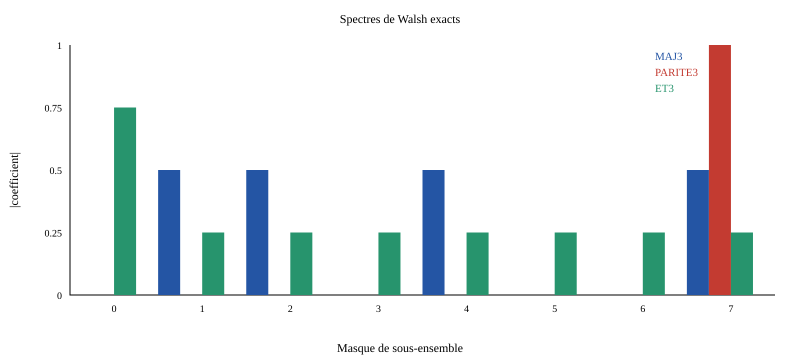

In [4]:
record SvgMarkup(string Content);
Formatter.Register<SvgMarkup>((v,w)=>w.Write(v.Content),"image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(SvgMarkup), "image/svg+xml");
// Le MIME image conserve les figures dans les lecteurs statiques de notebooks.
void AfficherSvg(SvgMarkup figure)
{
    display(figure, "image/svg+xml");
}
string F(double v)=>v.ToString("0.##",CultureInfo.InvariantCulture);
string Esc(string s)=>System.Security.SecurityElement.Escape(s);
string Barres(double[][] series,string[] noms,string title,string xlab,string ylab) {
 int W=800,H=360,L=70,R=25,Top=45,Bot=65; double ymax=Math.Max(1e-10,series.SelectMany(a=>a).Max());int count=series[0].Length;double span=(W-L-R)/(double)count;
 var b=new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}'><rect width='100%' height='100%' fill='white'/><text x='400' y='23' text-anchor='middle'>{Esc(title)}</text><path d='M {L} {Top} V {H-Bot} H {W-R}' stroke='black' fill='none'/>");string[] colors={"#2455a4","#c33b31","#27946d"};
 for(int j=0;j<series.Length;j++){for(int i=0;i<count;i++){double h=series[j][i]/ymax*(H-Top-Bot), w=span/(series.Length+1);b.Append($"<rect x='{F(L+i*span+j*w)}' y='{F(H-Bot-h)}' width='{F(w)}' height='{F(h)}' fill='{colors[j%3]}'/>");}b.Append($"<text x='{W-R-120}' y='{Top+15+j*16}' fill='{colors[j%3]}' font-size='11'>{Esc(noms[j])}</text>");}
 for(int i=0;i<count;i++)b.Append($"<text x='{F(L+(i+0.5)*span)}' y='{H-Bot+17}' font-size='10' text-anchor='middle'>{i}</text>");for(int i=0;i<=4;i++)b.Append($"<text x='{L-8}' y='{F(H-Bot-(H-Top-Bot)*i/4.0+4)}' text-anchor='end' font-size='10'>{F(ymax*i/4)}</text>");
 return b.Append($"<text x='400' y='{H-8}' text-anchor='middle'>{Esc(xlab)}</text><text transform='translate(18,180) rotate(-90)' text-anchor='middle'>{Esc(ylab)}</text></svg>").ToString();
}
var noms3=new[]{"MAJ3","PARITE3","ET3"};
AfficherSvg(new SvgMarkup(Barres(noms3.Select(n=>WalshRapide(fonctions3[n],3).Select(Math.Abs).ToArray()).ToArray(),noms3,"Spectres de Walsh exacts","Masque de sous-ensemble","|coefficient|")));

Les barres montrent les huit sous-ensembles : MAJ3 concentre son énergie sur les trois singletons et le triple ; PARITE3 n'a que le triple ; ET3 mobilise les huit caractères.

In [5]:
var chrono=new Stopwatch();var benchNaif=new List<(int n,double s)>();var benchRapide=new List<(int n,double s)>();var rngBench=new Random(42);
foreach(int n in new[]{8,10,12}) {var f=Enumerable.Range(0,1<<n).Select(_=>rngBench.Next(2)==0?-1.0:1.0).ToArray();chrono.Restart();var a=WalshNaif(f,n);chrono.Stop();double tn=chrono.Elapsed.TotalSeconds;chrono.Restart();var b=WalshRapide(f,n);chrono.Stop();double tr=chrono.Elapsed.TotalSeconds;if(!Proches(a,b,1e-8))throw new Exception("Benchmark incohérent");benchNaif.Add((n,tn));benchRapide.Add((n,tr));Console.WriteLine($"n={n} : naïf {tn:F6}s ; papillon {tr:F6}s ; ratio {tn/tr:F1}");}
foreach(int n in new[]{16,18}) {var f=Enumerable.Range(0,1<<n).Select(_=>rngBench.Next(2)==0?-1.0:1.0).ToArray();chrono.Restart();FWHT(f);chrono.Stop();benchRapide.Add((n,chrono.Elapsed.TotalSeconds));Console.WriteLine($"n={n} : papillon {chrono.Elapsed.TotalSeconds:F6}s, {f.Length} coefficients");}
Console.WriteLine("Le calcul naïf évalue les mêmes 4^n termes sans matérialiser la matrice entière.");

n=8 : naïf 0.000467s ; papillon 0.000027s ; ratio 17.5


n=10 : naïf 0.006067s ; papillon 0.000050s ; ratio 120.4


n=12 : naïf 0.199405s ; papillon 0.000159s ; ratio 1251.8


n=16 : papillon 0.003235s, 65536 coefficients


n=18 : papillon 0.015868s, 262144 coefficients


Le calcul naïf évalue les mêmes 4^n termes sans matérialiser la matrice entière.


Les temps dépendent du matériel. Les budgets restent n=8,10,12 pour les deux méthodes et n=16,18 pour le papillon ; la somme directe n'alloue pas la matrice complète, mais conserve ses termes et sa complexité.

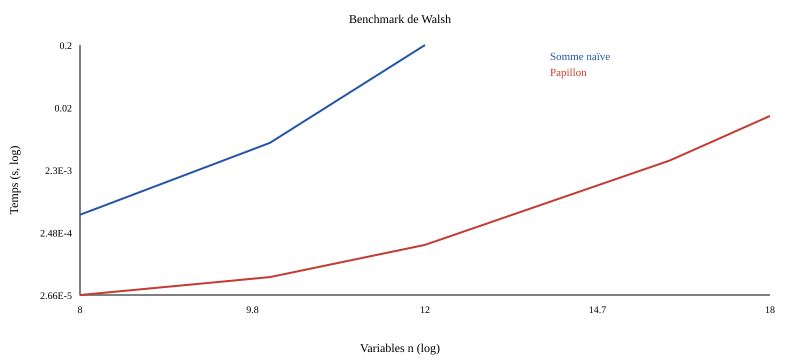

In [6]:
string FT(double v) => v != 0 && (Math.Abs(v)<0.01 || Math.Abs(v)>=10000) ? v.ToString("0.##E+0",CultureInfo.InvariantCulture) : F(v);
string Lignes(double[][] xs,double[][] ys,string[] noms,string title,string xlabel,string ylabel,bool logX=false,bool logY=false) {
 const int W=800,H=360,L=80,R=30,Top=45,Bot=65;double T(double v,bool log)=>log?Math.Log10(Math.Max(v,1e-16)):v;
 var tx=xs.Select(a=>a.Select(v=>T(v,logX)).ToArray()).ToArray();var ty=ys.Select(a=>a.Select(v=>T(v,logY)).ToArray()).ToArray();double x0=tx.SelectMany(a=>a).Min(),x1=tx.SelectMany(a=>a).Max(),y0=ty.SelectMany(a=>a).Min(),y1=ty.SelectMany(a=>a).Max();if(x1==x0)x1++;if(y1==y0)y1++;
 double Xp(double v)=>L+(v-x0)/(x1-x0)*(W-L-R);double Yp(double v)=>H-Bot-(v-y0)/(y1-y0)*(H-Top-Bot);
 var b=new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}'><rect width='100%' height='100%' fill='white'/><text x='400' y='23' text-anchor='middle'>{Esc(title)}</text><path d='M {L} {Top} V {H-Bot} H {W-R}' stroke='black' fill='none'/>");string[] colors={"#2455a4","#c33b31","#27946d"};
 for(int j=0;j<tx.Length;j++){string pts=string.Join(" ",tx[j].Select((v,i)=>$"{F(Xp(v))},{F(Yp(ty[j][i]))}"));b.Append($"<polyline points='{pts}' fill='none' stroke='{colors[j%3]}' stroke-width='2'/><text x='{W-R-220}' y='{Top+15+j*16}' fill='{colors[j%3]}' font-size='11'>{Esc(noms[j])}</text>");}
 for(int i=0;i<=4;i++){double xv=x0+(x1-x0)*i/4,yv=y0+(y1-y0)*i/4;b.Append($"<text x='{F(Xp(xv))}' y='{H-Bot+18}' text-anchor='middle' font-size='10'>{FT(logX?Math.Pow(10,xv):xv)}</text><text x='{L-8}' y='{F(Yp(yv)+4)}' text-anchor='end' font-size='10'>{FT(logY?Math.Pow(10,yv):yv)}</text>");}
 return b.Append($"<text x='400' y='{H-8}' text-anchor='middle'>{Esc(xlabel)}</text><text transform='translate(18,180) rotate(-90)' text-anchor='middle'>{Esc(ylabel)}</text></svg>").ToString();
}
AfficherSvg(new SvgMarkup(Lignes(new[]{benchNaif.Select(z=>(double)z.n).ToArray(),benchRapide.Select(z=>(double)z.n).ToArray()},new[]{benchNaif.Select(z=>z.s).ToArray(),benchRapide.Select(z=>z.s).ToArray()},new[]{"Somme naïve","Papillon"},"Benchmark de Walsh","Variables n (log)","Temps (s, log)",true,true)));

La représentation logarithmique compare les coûts mesurés ; les durées sont propres à cette exécution et les rapports ne sont pas une garantie de vitesse sur une autre machine.

### Exercice 1 — EXACT2 et PTF de degré 1
Construisez la table EXACT2 sur quatre bits, son spectre et la recherche des 3⁵ poids ternaires de degré au plus 1. Fournissez une table de 16 signes ; le garde compare toutes les lignes puis vérifie reconstruction et Parseval.

In [7]:
record SolutionExact2(int[] Table,double[] Spectre,int Nombre);
bool VerifierExact2(SolutionExact2 resultat){
 if(resultat==null || resultat.Table==null || resultat.Spectre==null || resultat.Table.Length!=16 || resultat.Spectre.Length!=16 || resultat.Table.Any(v=>v!=1&&v!=-1) || resultat.Spectre.Any(v=>!double.IsFinite(v)))return false;
 var table=resultat.Table;for(int i=0;i<16;i++)if(table[i]!=(BitOperations.PopCount((uint)i)==2?1:-1))return false;
 var f=table.Select(v=>(double)v).ToArray();if(!Proches(resultat.Spectre,WalshNaif(f,4)) || !Proches(Reconstruire(resultat.Spectre,4),f) || Math.Abs(resultat.Spectre.Sum(v=>v*v)-1)>1e-10)return false;
 int[] masks={0,1,2,4,8};int total=0;
 for(int id=0;id<243;id++){int x=id;var w=new int[5];for(int j=0;j<5;j++){w[j]=x%3-1;x/=3;}bool ok=true;for(int i=0;i<16;i++)if(Signe(Enumerable.Range(0,5).Sum(j=>w[j]*Caractere(i,masks[j])))!=table[i]){ok=false;break;}if(ok)total++;}
 return resultat.Nombre==total;
}
SolutionExact2 resultatEx1=null; // TODO : table, spectre et nombre de PTF de degré <= 1
Console.WriteLine(resultatEx1==null?"Exercice 1 à compléter":$"Solution valide : {VerifierExact2(resultatEx1)}");

Exercice 1 à compléter


## 2. Coefficients exacts et poids ternaires
Un polynôme de seuil ternaire utilise des poids dans {−1,0,+1}, tandis que les coefficients de Fourier sont rationnels et uniques. On énumère les 3⁴ = 81 poids pour chacune des 16 fonctions de deux variables et on relève degré Fourier, degré PTF minimal et nombre de représentations minimales.

In [8]:
IEnumerable<int[]> Ternaires(int n) {int total=1;for(int i=0;i<n;i++)total*=3;for(int v=0;v<total;v++){int x=v;var w=new int[n];for(int j=n-1;j>=0;j--){w[j]=x%3-1;x/=3;}yield return w;}}
int[] TablePTF(int n,int[] masks,int[] w)=>Enumerable.Range(0,1<<n).Select(i=>Signe(masks.Select((mask,j)=>w[j]*Caractere(i,mask)).Sum())).ToArray();
var noms2=new Dictionary<string,int[]>();
foreach(var (nom,f) in new (string,Func<int,int,int>)[]{("AND",AND),("NAND",(a,b)=>-AND(a,b)),("OR",OR),("NOR",(a,b)=>-OR(a,b)),("XOR",XOR),("XNOR",XNOR),("x1 implique x2",(a,b)=>OR(-a,b)),("non (x1 implique x2)",(a,b)=>-OR(-a,b)),("x2 implique x1",(a,b)=>OR(-b,a)),("non (x2 implique x1)",(a,b)=>-OR(-b,a))})noms2[nom]=Enumerable.Range(0,4).Select(i=>f(X(i,0),X(i,1))).ToArray();
noms2["constante +1"]=Enumerable.Repeat(1,4).ToArray();noms2["constante -1"]=Enumerable.Repeat(-1,4).ToArray();
noms2["x1"]=Enumerable.Range(0,4).Select(i=>X(i,0)).ToArray();noms2["non x1"]=noms2["x1"].Select(v=>-v).ToArray();noms2["x2"]=Enumerable.Range(0,4).Select(i=>X(i,1)).ToArray();noms2["non x2"]=noms2["x2"].Select(v=>-v).ToArray();
int[] masks2={0,1,2,3};
foreach(var (nom,table) in noms2){var reps=Ternaires(4).Where(w=>TablePTF(2,masks2,w).SequenceEqual(table)).ToList();int D(int[] w)=>Enumerable.Range(0,4).Where(j=>w[j]!=0).Select(j=>BitOperations.PopCount((uint)masks2[j])).DefaultIfEmpty(0).Max();int dm=reps.Min(D);var premiers=reps.Where(w=>D(w)==dm).ToList();Console.WriteLine($"{nom,-23} Fourier {Degre(WalshRapide(table.Select(v=>(double)v).ToArray(),2))}, PTF {dm}, représentations {premiers.Count}, exemple [{string.Join(",",premiers[0])}]");}
int preserveTronc=0,preserveArr=0;
foreach(var table in noms2.Values){var a=WalshRapide(table.Select(v=>(double)v).ToArray(),2);var tr=a.Select(v=>(int)Math.Truncate(v)).ToArray();var ar=a.Select(v=>(int)Math.Round(v)).ToArray();if(TablePTF(2,masks2,tr).SequenceEqual(table))preserveTronc++;if(TablePTF(2,masks2,ar).SequenceEqual(table))preserveArr++;}
Console.WriteLine($"Troncature : {preserveTronc}/16 ; arrondi : {preserveArr}/16 fonctions préservées.");

AND                     Fourier 2, PTF 1, représentations 1, exemple [-1,1,1,0]


NAND                    Fourier 2, PTF 1, représentations 2, exemple [0,-1,-1,0]


OR                      Fourier 2, PTF 1, représentations 2, exemple [0,1,1,0]


NOR                     Fourier 2, PTF 1, représentations 1, exemple [-1,-1,-1,0]


XOR                     Fourier 2, PTF 2, représentations 2, exemple [-1,0,0,-1]


XNOR                    Fourier 2, PTF 2, représentations 2, exemple [-1,0,0,1]


... (7 outputs left out)

non x1                  Fourier 1, PTF 1, représentations 2, exemple [-1,-1,0,0]


x2                      Fourier 1, PTF 1, représentations 2, exemple [-1,0,1,0]


non x2                  Fourier 1, PTF 1, représentations 2, exemple [-1,0,-1,0]


Troncature : 8/16 ; arrondi : 8/16 fonctions préservées.


OR a un degré Fourier 2 mais une PTF ternaire de degré 1 ; XOR exige le caractère d'ordre 2. Les 16 fonctions sont représentées par au moins une PTF, mais la quantification naïve des coefficients n'en préserve que 8 sur 16.

## 3. Routage par Sinkhorn
On normalise alternativement lignes et colonnes pendant 200 itérations, pour des scores aléatoires à deux températures et des blocs d'ex æquos. Une matrice bistochastique n'est pas forcément une permutation. Des scores distincts ne suffisent pas à garantir une affectation optimale unique : c'est l'unicité de cette affectation qui compte.

In [9]:
record SinkResult(double[,] P,double[] Erreurs,double[] Normes);
SinkResult Sinkhorn(double[,] M,double tau,int iterations=200) {
 int n=M.GetLength(0);var p=new double[n,n];for(int i=0;i<n;i++)for(int j=0;j<n;j++)p[i,j]=Math.Exp(M[i,j]/tau);
 var errs=new double[iterations];var norms=new double[iterations];
 for(int k=0;k<iterations;k++){
  for(int i=0;i<n;i++){double s=0;for(int j=0;j<n;j++)s+=p[i,j];for(int j=0;j<n;j++)p[i,j]/=s;}
  for(int j=0;j<n;j++){double s=0;for(int i=0;i<n;i++)s+=p[i,j];for(int i=0;i<n;i++)p[i,j]/=s;}
  double err=0,norm=0;for(int i=0;i<n;i++){double row=0,col=0;for(int j=0;j<n;j++){row+=p[i,j];col+=p[j,i];norm+=p[i,j]*p[i,j];}err=Math.Max(err,Math.Max(Math.Abs(row-1),Math.Abs(col-1)));}errs[k]=err;norms[k]=norm;
 }return new SinkResult(p,errs,norms);
}
IEnumerable<int[]> Permutations(int n) {var p=Enumerable.Range(0,n).ToArray();IEnumerable<int[]> Rec(int k){if(k==n){yield return (int[])p.Clone();yield break;}for(int j=k;j<n;j++){(p[k],p[j])=(p[j],p[k]);foreach(var x in Rec(k+1))yield return x;(p[k],p[j])=(p[j],p[k]);}}return Rec(0);}
(int Count,double Cost) PermsMin(double[,] P){int n=P.GetLength(0);var costs=Permutations(n).Select(a=>Enumerable.Range(0,n).Sum(i=>Math.Pow(P[i,a[i]]-1,2))).ToArray();double min=costs.Min();return (costs.Count(v=>Math.Abs(v-min)<1e-12),min);}
int Ambigues(double[,] P){int n=P.GetLength(0),c=0;for(int i=0;i<n;i++){double max=Enumerable.Range(0,n).Max(j=>P[i,j]);if(Enumerable.Range(0,n).Count(j=>Math.Abs(P[i,j]-max)<1e-6)>1)c++;}return c;}
var randSk=new Random(7);double Gauss(){double u=1-randSk.NextDouble(),v=1-randSk.NextDouble();return Math.Sqrt(-2*Math.Log(u))*Math.Cos(2*Math.PI*v);}
var libre=new double[4,4];var ties=new double[4,4];for(int i=0;i<4;i++)for(int j=0;j<4;j++){libre[i,j]=2*Gauss();ties[i,j]=(i/2==j/2)?2:-2;}
var cas=new Dictionary<string,SinkResult>{{"distinct tau=0.1",Sinkhorn(libre,0.1)},{"distinct tau=1",Sinkhorn(libre,1)},{"ex æquos tau=1",Sinkhorn(ties,1)}};
foreach(var (nom,z) in cas){var pm=PermsMin(z.P);Console.WriteLine($"{nom} : erreur marges {z.Erreurs.Last():E2} ; somme P²={z.Normes.Last():F4} ; lignes ambiguës {Ambigues(z.P)}/4 ; permutations minimales {pm.Count}");for(int i=0;i<4;i++)Console.WriteLine("  "+string.Join(" ",Enumerable.Range(0,4).Select(j=>z.P[i,j].ToString("F3"))));}

distinct tau=0.1 : erreur marges 4.40E-003 ; somme P²=3.9464 ; lignes ambiguës 0/4 ; permutations minimales 1


  0.006 0.000 0.000 0.994


  0.004 0.000 1.000 0.000


  0.000 0.990 0.000 0.006


  0.989 0.010 0.000 0.000


distinct tau=1 : erreur marges 0.00E+000 ; somme P²=1.7235 ; lignes ambiguës 0/4 ; permutations minimales 1


... (5 outputs left out)

  0.491 0.491 0.009 0.009


  0.491 0.491 0.009 0.009


  0.009 0.009 0.491 0.491


  0.009 0.009 0.491 0.491


La température module la diffusion. Dans les blocs ex æquo, plusieurs permutations peuvent partager le coût minimal ; un arrondi en choisit une. Les scores tirés par .NET ne sont pas ceux du générateur NumPy ; les trois protocoles, leurs tailles et leurs budgets sont identiques.

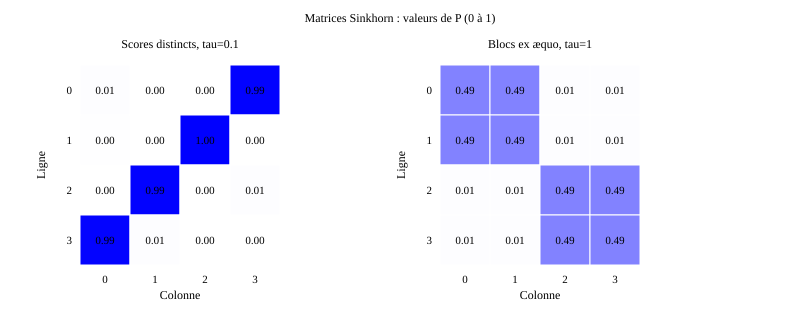

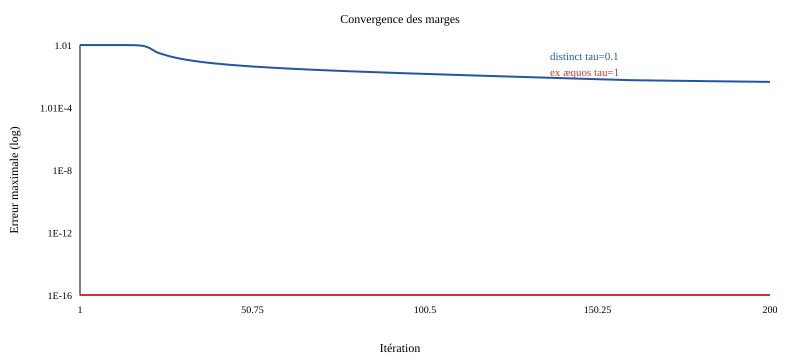

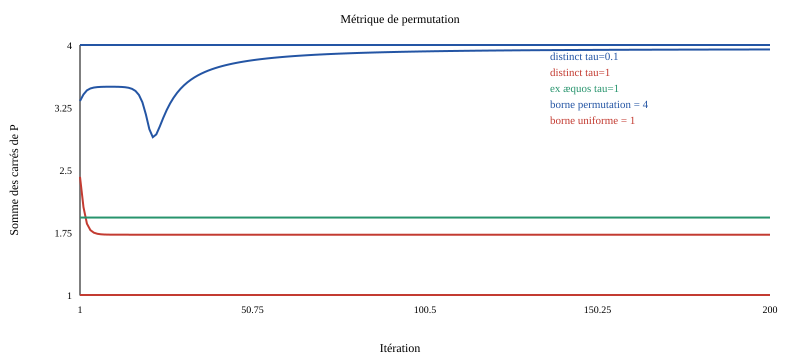

In [10]:
string HeatPair(double[,] a,double[,] b) {
 const int W=800,H=310;var s=new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}'><rect width='100%' height='100%' fill='white'/><text x='400' y='22' text-anchor='middle'>Matrices Sinkhorn : valeurs de P (0 à 1)</text>");
 var arr=new[]{a,b};string[] labs={"Scores distincts, tau=0.1","Blocs ex æquo, tau=1"};for(int k=0;k<2;k++){int x0=80+k*360,y0=65;s.Append($"<text x='{x0+100}' y='48' text-anchor='middle'>{labs[k]}</text>");for(int i=0;i<4;i++)for(int j=0;j<4;j++){double v=arr[k][i,j];int t=(int)Math.Round(255*(1-v));s.Append($"<rect x='{x0+50*j}' y='{y0+50*i}' width='50' height='50' fill='rgb({t},{t},255)' stroke='white'/><text x='{x0+50*j+25}' y='{y0+50*i+29}' text-anchor='middle' font-size='11'>{v:F2}</text>");}for(int q=0;q<4;q++)s.Append($"<text x='{x0+50*q+25}' y='{y0+218}' text-anchor='middle' font-size='11'>{q}</text><text x='{x0-8}' y='{y0+50*q+29}' text-anchor='end' font-size='11'>{q}</text>");s.Append($"<text x='{x0+100}' y='299' text-anchor='middle'>Colonne</text><text transform='translate({x0-35},165) rotate(-90)' text-anchor='middle'>Ligne</text>");}return s.Append("</svg>").ToString();
}
AfficherSvg(new SvgMarkup(HeatPair(cas["distinct tau=0.1"].P,cas["ex æquos tau=1"].P)));
var its=Enumerable.Range(1,200).Select(i=>(double)i).ToArray();var clefs=cas.Keys.ToArray();
AfficherSvg(new SvgMarkup(Lignes(new[]{its,its},new[]{cas[clefs[0]].Erreurs,cas[clefs[2]].Erreurs},new[]{clefs[0],clefs[2]},"Convergence des marges","Itération","Erreur maximale (log)",false,true)));
AfficherSvg(new SvgMarkup(Lignes(new[]{its,its,its,its,its},clefs.Select(k=>cas[k].Normes).Concat(new[]{Enumerable.Repeat(4.0,200).ToArray(),Enumerable.Repeat(1.0,200).ToArray()}).ToArray(),clefs.Concat(new[]{"borne permutation = 4","borne uniforme = 1"}).ToArray(),"Métrique de permutation","Itération","Somme des carrés de P")));

Les cartes et trajectoires montrent la limite et la convergence ; pour une bistochastique 4×4, la somme des carrés vaut 1 à l'uniforme et 4 à une permutation. Les quatre permutations ex æquo ont même coût : le choix d'un arrondi n'est pas une preuve d'unicité.

### Exercice 2 — Une ligne de scores uniforme
Étudiez une matrice 3×3 dont la première ligne est uniforme et les deux autres distinctes. Les normalisations de colonnes peuvent rendre cette première ligne non uniforme. Complétez la matrice P après 200 itérations ; le garde vérifie toutes les cases et affiche ensuite les ambiguïtés et le nombre de permutations minimales.

In [11]:
var scoresEx2=new double[,]{{0,0,0},{2,0,-1},{-2,1,0}};
bool VerifierSinkhorn(Func<double[,],double,int,double[,]> fonction){
 if(fonction==null)return false;
 var essais=new[]{(Scores:scoresEx2,Tau:1.0,Iterations:200),(Scores:new double[,]{{2,-1,0,1},{0,3,-2,1},{1,0,2,-1},{-2,1,0,2}},Tau:0.8,Iterations:200)};
 foreach(var (scores,tau,iterations) in essais){var p=fonction((double[,])scores.Clone(),tau,iterations);int n=scores.GetLength(0);if(p==null||p.GetLength(0)!=n||p.GetLength(1)!=n)return false;var attendu=Sinkhorn(scores,tau,iterations).P;
  for(int i=0;i<n;i++){double row=0,col=0;for(int j=0;j<n;j++){if(!double.IsFinite(p[i,j])||Math.Abs(p[i,j]-attendu[i,j])>1e-8)return false;row+=p[i,j];col+=p[j,i];}if(Math.Abs(row-1)>1e-8||Math.Abs(col-1)>1e-8)return false;}
  if(Ambigues(p)!=Ambigues(attendu)||PermsMin(p).Count!=PermsMin(attendu).Count)return false;
 }return true;
}
Func<double[,],double,int,double[,]> monSinkhorn=null; // TODO : exponentier puis normaliser lignes et colonnes
if(monSinkhorn==null || !VerifierSinkhorn(monSinkhorn))Console.WriteLine("Exercice 2 à compléter ou résultat invalide");
else {var p=monSinkhorn((double[,])scoresEx2.Clone(),1,200);Console.WriteLine($"Valide ; lignes ambiguës : {Ambigues(p)} ; permutations minimales : {PermsMin(p).Count}");}

Exercice 2 à compléter ou résultat invalide


## 4. Quantification et recherche discrète
Sur n=4, le dictionnaire des caractères de degré ≤2 contient 11 colonnes et la table complète de ses 2⁴ assignations. Une cible est construite à partir de six poids ternaires. Les moindres carrés sont calculés par Math.NET, puis arrondis ; l'oracle E compte exactement les erreurs de classification. On compare greedy et l'énumération exhaustive de 3¹¹=177 147 poids.

In [12]:
var masks4=Enumerable.Range(0,16).Where(j=>BitOperations.PopCount((uint)j)<=2).ToArray();int m4=masks4.Length;
var A=Matrix<double>.Build.Dense(16,m4,(i,j)=>Caractere(i,masks4[j]));int[] wstar=new int[m4];int[] idx={0,2,3,5,7,8};int[] vals={1,-1,1,1,-1,1};for(int j=0;j<idx.Length;j++)wstar[idx[j]]=vals[j];
var cible=TablePTF(4,masks4,wstar);
int Energie(int[] w)=>TablePTF(4,masks4,w).Zip(cible).Count(z=>z.First!=z.Second);
var targetVector=MathNet.Numerics.LinearAlgebra.Vector<double>.Build.DenseOfEnumerable(cible.Select(v=>(double)v));var ls=A.QR().Solve(targetVector);
int erreurContinue=Enumerable.Range(0,16).Count(i=>Signe(A.Row(i).DotProduct(ls))!=cible[i]);
var wq=ls.Select(v=>Math.Clamp((int)Math.Round(v),-1,1)).ToArray();
(int[] W,int E,int Passes) Greedy(int[] initial,int maxPasses=100){var w=(int[])initial.Clone();int e=Energie(w),pass=0;while(pass<maxPasses){pass++;bool changed=false;for(int j=0;j<w.Length;j++)foreach(int v in new[]{-1,0,1}){if(v==w[j])continue;var t=(int[])w.Clone();t[j]=v;int e2=Energie(t);if(e2<e){w=t;e=e2;changed=true;}}if(!changed)break;}return (w,e,pass);}
var greedy=Greedy(wq);int minE=int.MaxValue,nopt=0,count=0;chrono.Restart();foreach(var w in Ternaires(m4)){int e=Energie(w);count++;if(e<minE){minE=e;nopt=1;}else if(e==minE)nopt++;}chrono.Stop();
Console.WriteLine($"Dictionnaire m={m4} ; E(w*)={Energie(wstar)} ; erreur continue {erreurContinue}/16");
Console.WriteLine($"Quantification [{string.Join(",",wq)}] : E={Energie(wq)}/16 ; greedy E={greedy.E}/16 en {greedy.Passes} balayage(s)");
Console.WriteLine($"Exhaustif {count} vecteurs en {chrono.Elapsed.TotalSeconds:F3}s : min E={minE}, nombre d'optimums={nopt}");

Dictionnaire m=11 ; E(w*)=0 ; erreur continue 0/16


Quantification [1,0,0,0,0,0,0,0,0,0,0] : E=2/16 ; greedy E=2/16 en 1 balayage(s)


Exhaustif 177147 vecteurs en 5.552s : min E=0, nombre d'optimums=92


L'oracle porte sur toutes les 16 entrées. Il permet de distinguer la perte à la quantification, le blocage éventuel de greedy et l'optimum global. Les 177 147 poids exhaustifs servent de vérité terrain ; les temps et l'arrondi au voisinage de demi-entiers dépendent du calcul numérique. Ici la quantification et greedy donnent chacun deux erreurs sur 16 ; l’énumération trouve 92 optimums à erreur nulle.

### Metropolis et parallel tempering
Une proposition modifie une coordonnée par l'une des deux autres valeurs, uniformément : elle est symétrique. Metropolis accepte selon min(1, exp(−ΔE/T)). Le parallel tempering utilise quatre températures (0,3 ; 0,6 ; 1,2 ; 2,5), échange des voisins toutes les 10 itérations et partage équitablement le budget d'évaluations entre répliques.

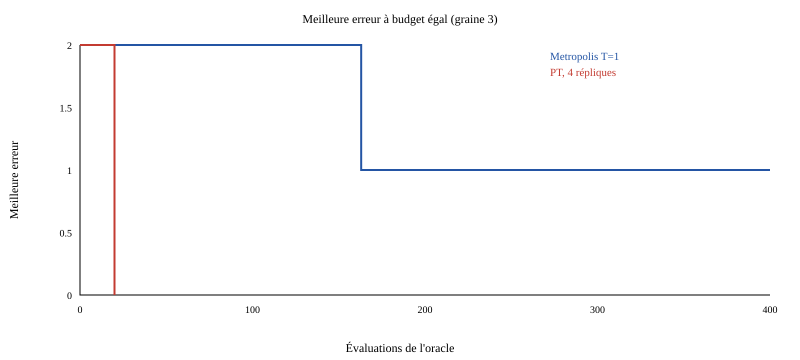

Metropolis : 8/8 résolus, médiane 392, plage 155..800


PT : 8/8 résolus, médiane 472, plage 20..1228


In [13]:
record Recherche(int[] W,int E,List<int> Historique);
Recherche Metropolis(int[] initial,double temp,int budget,int seed){
 var rng=new Random(seed);var w=(int[])initial.Clone();int e=Energie(w),best=e;var bestW=(int[])w.Clone();var hist=new List<int>{best};
 for(int it=0;it<budget;it++){int j=rng.Next(w.Length),v;do{v=rng.Next(3)-1;}while(v==w[j]);var cand=(int[])w.Clone();cand[j]=v;int d=Energie(cand)-e;if(d<=0||rng.NextDouble()<Math.Exp(-d/temp)){w=cand;e+=d;if(e<best){best=e;bestW=(int[])w.Clone();}}hist.Add(best);if(best==0)break;}
 return new Recherche(bestW,best,hist);
}
Recherche Tempering(int[] initial,double[] temps,int iterations,int seed,int swapToutes=10){
 var rng=new Random(seed);int K=temps.Length;var states=Enumerable.Range(0,K).Select(_=>(int[])initial.Clone()).ToArray();var energies=states.Select(Energie).ToArray();int best=energies[0];var bestW=(int[])states[0].Clone();var hist=new List<int>{best};
 for(int it=0;it<iterations;it++){
  for(int k=0;k<K;k++){int j=rng.Next(m4),v;do{v=rng.Next(3)-1;}while(v==states[k][j]);var cand=(int[])states[k].Clone();cand[j]=v;int d=Energie(cand)-energies[k];if(d<=0||rng.NextDouble()<Math.Exp(-d/temps[k])){states[k]=cand;energies[k]+=d;}}
  if((it+1)%swapToutes==0 && K>1){int k=rng.Next(K-1);double loga=(1/temps[k]-1/temps[k+1])*(energies[k]-energies[k+1]);if(loga>=0||rng.NextDouble()<Math.Exp(loga)){(states[k],states[k+1])=(states[k+1],states[k]);(energies[k],energies[k+1])=(energies[k+1],energies[k]);}}
  int current=energies.Min();if(current<best){best=current;bestW=(int[])states[Array.IndexOf(energies,current)].Clone();}hist.Add(best);if(best==0)break;
 }return new Recherche(bestW,best,hist);
}
double[] tempsPt={0.3,0.6,1.2,2.5};int K=tempsPt.Length;
var sa3=Metropolis(wq,1,400,3);var pt3=Tempering(wq,tempsPt,400/K,3);
(double[] X,double[] Y) Escalier(List<int> hist,int pas){var xs=new List<double>{0};var ys=new List<double>{hist[0]};for(int i=1;i<hist.Count;i++){xs.Add(i*pas);ys.Add(hist[i-1]);xs.Add(i*pas);ys.Add(hist[i]);}return (xs.ToArray(),ys.ToArray());}
var saStep=Escalier(sa3.Historique,1);var ptStep=Escalier(pt3.Historique,K);
AfficherSvg(new SvgMarkup(Lignes(new[]{saStep.X,ptStep.X},new[]{saStep.Y,ptStep.Y},new[]{"Metropolis T=1","PT, 4 répliques"},"Meilleure erreur à budget égal (graine 3)","Évaluations de l'oracle","Meilleure erreur")));
double Mediane(List<int> a){var s=a.OrderBy(v=>v).ToArray();return s.Length%2==1?s[s.Length/2]:(s[s.Length/2-1]+s[s.Length/2])/2.0;}
var evalsSa=new List<int>();var evalsPt=new List<int>();for(int seed=0;seed<8;seed++){var sa=Metropolis(wq,1,2000,seed);var pt=Tempering(wq,tempsPt,2000/K,seed);if(sa.E==0)evalsSa.Add(sa.Historique.Count-1);if(pt.E==0)evalsPt.Add((pt.Historique.Count-1)*K);}
Console.WriteLine($"Metropolis : {evalsSa.Count}/8 résolus, médiane {(evalsSa.Count>0?Mediane(evalsSa).ToString("F0"):"N/A")}, plage {(evalsSa.Count>0?$"{evalsSa.Min()}..{evalsSa.Max()}":"N/A")}");
Console.WriteLine($"PT : {evalsPt.Count}/8 résolus, médiane {(evalsPt.Count>0?Mediane(evalsPt).ToString("F0"):"N/A")}, plage {(evalsPt.Count>0?$"{evalsPt.Min()}..{evalsPt.Max()}":"N/A")}");

Les trajectoires montrent le meilleur score atteint, pas l'état courant. Les résultats aléatoires dépendent du générateur .NET ; il serait incorrect de déduire une domination générale d'une méthode à partir d'une seule graine. Chaque réplique de PT consomme une évaluation par itération. Dans ce tirage, les huit graines réussissent pour les deux méthodes : médiane 392 évaluations pour Metropolis et 472 pour PT.

In [14]:
int NbEchecs(string methode,int budget){int echecs=0;for(int seed=0;seed<8;seed++){Recherche z=methode switch {"sa05"=>Metropolis(wq,0.5,budget,seed),"sa10"=>Metropolis(wq,1,budget,seed),"pt"=>Tempering(wq,tempsPt,budget/K,seed),_=>throw new ArgumentException(methode)};if(z.E>0)echecs++;}return echecs;}
foreach(int budget in new[]{100,300,1000})Console.WriteLine($"Budget {budget} : greedy 8, SA T=0.5 {NbEchecs("sa05",budget)}, SA T=1 {NbEchecs("sa10",budget)}, PT {NbEchecs("pt",budget)} échecs sur 8 graines");

Budget 100 : greedy 8, SA T=0.5 4, SA T=1 8, PT 6 échecs sur 8 graines


Budget 300 : greedy 8, SA T=0.5 2, SA T=1 5, PT 4 échecs sur 8 graines


Budget 1000 : greedy 8, SA T=0.5 2, SA T=1 0, PT 2 échecs sur 8 graines


Le tableau mesure les échecs à budgets identiques plutôt que de choisir une trajectoire favorable. Greedy est déterministe et bloque sur cette instance ; les méthodes stochastiques explorent au-delà. L'ordre des résultats de SA et PT dépend du tirage. À 1 000 évaluations, cette exécution donne 0 échec pour SA T=1 et 2 pour PT ; à 100, elle en donne respectivement 8 et 6.

### Exercice 3 — Comparer plusieurs budgets
Écrivez une fonction qui renvoie `(E(wq), E_greedy, échecs_SA, échecs_PT)` pour un budget donné et huit graines. Comparez 50, 100 et 300 évaluations et discutez la variabilité. En prolongement, essayez un vecteur cible plus dense ou un dictionnaire de degré au plus 1 avec cible non réalisable ; calculez alors l'optimum exhaustif de 3⁵ poids.

In [15]:
bool VerifierMesures(Func<int,int[]> fonction){
 if(fonction==null)return false;
 foreach(int budget in new[]{50,100,300}){var resultat=fonction(budget);if(resultat==null||resultat.Length!=4)return false;var attendu=new[]{Energie(wq),greedy.E,NbEchecs("sa10",budget),NbEchecs("pt",budget)};if(!resultat.SequenceEqual(attendu))return false;}
 return true;
}
Func<int,int[]> mesuresBudget=null; // TODO : quatre mesures à ce budget sur huit graines
Console.WriteLine(mesuresBudget==null?"Exercice 3 à compléter":$"Mesures valides : {VerifierMesures(mesuresBudget)}");

Exercice 3 à compléter


## 5. Pont avec les portes locales
Un circuit de deux couches calcule AND(OR(x₁,x₂), XNOR(x₃,x₄)). Sa table complète a un spectre exact dans la même base que les fonctions précédentes : la vue locale décrit le câblage, la vue spectrale décrit la fonction globale.

In [16]:
var circuit=Enumerable.Range(0,16).Select(i=>(double)AND(OR(X(i,0),X(i,1)),XNOR(X(i,2),X(i,3)))).ToArray();var spectreCircuit=WalshRapide(circuit,4);
Console.WriteLine($"Circuit : AND(OR(x1,x2), XNOR(x3,x4)) ; degré {Degre(spectreCircuit)} ; {spectreCircuit.Count(v=>Math.Abs(v)>1e-12)}/16 coefficients non nuls");
foreach(var (v,i) in spectreCircuit.Select((v,i)=>(v,i)).Where(z=>Math.Abs(z.v)>1e-12))Console.WriteLine($"  masque {i} : {v:+0.####;-0.####;0}");
Console.WriteLine($"Reconstruction exacte : {Proches(Reconstruire(spectreCircuit,4),circuit)}");

Circuit : AND(OR(x1,x2), XNOR(x3,x4)) ; degré 4 ; 8/16 coefficients non nuls


  masque 0 : -0.25


  masque 1 : +0.25


  masque 2 : +0.25


  masque 3 : -0.25


  masque 12 : +0.75


  masque 13 : +0.25


  masque 14 : +0.25


  masque 15 : -0.25


Reconstruction exacte : True


Le circuit local possède un spectre de degré 4 avec huit coefficients non nuls. Ces deux représentations décrivent la même fonction et exposent des structures différentes.

## À retenir
| Outil | Résultat |
|---|---|
| Walsh et FWHT | coefficients exacts, reconstruction et Parseval |
| PTF ternaire | poids discrets, non uniques et distincts des coefficients Fourier |
| Sinkhorn | relaxation bistochastique, pas nécessairement une permutation |
| Recherche discrète | oracle exact, comparaison d'évaluations à budget égal |

## Vérifiez votre compréhension
Pourquoi quantifier des coefficients exacts peut-il changer la fonction ?
<details><summary>Réponse</summary>L'arrondi change les valeurs du polynôme, qui peuvent franchir le seuil.</details>

## Pour aller plus loin
Consulter le [carnet Python](SL-12b-SpectralLogicSynthesis.ipynb) pour les références et le contexte historique.